# How is MODIS/VIIRS capturing the fire intensity

In [2]:
import os
import pdb
import time
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from geopandas.tools import sjoin
from tqdm import tqdm

In [3]:
# Read data and transform to a Geopandas DataFrame

points = pd.read_csv('../data/modis_points/fire_archive_M-C61_283193.csv')
fire_points = gpd.GeoDataFrame(
    points, geometry=gpd.points_from_xy(points.longitude, points.latitude))

fire_points = fire_points.set_crs('epsg:4326').to_crs('EPSG:5070')

/Users/topcat/miniconda3/envs/fire/lib/python3.9/site-packages/geopandas/array.py:275: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  return GeometryArray(vectorized.points_from_xy(x, y, z), crs=crs)


In [4]:
### Load Shape and do a spatial join

# States that I don't want from the US
not_continental = ['Puerto Rico', 'Alaska', 'Hawaii']

# Read in NaturalEarth data and filter to US states 
world = gpd.read_file('../data/ne_10m_admin_1_states_provinces.zip')
us = (
    world[(world.iso_a2 == 'US') & (~world.name.isin(not_continental))]
    .filter(['name', 'code_local', 'geometry'])
    .to_crs('EPSG:5070')
)

# Load up all MTBS (1989 to 2022) and merge with the US state data
mtbs_perimeters = gpd.read_file('../data/mtbs_perims_DD/mtbs_perims_DD.shp')
mtbs_perimeters['date'] = mtbs_perimeters.Ig_Date.apply(lambda x: pd.to_datetime(x, format='%Y-%m-%d'))
mtbs_perimeters = mtbs_perimeters.to_crs('EPSG:5070')

# Spatial join :) 
mtbs_per_us = sjoin(mtbs_perimeters, us, how='left')
mtbs_per_us = mtbs_per_us.filter(['Event_ID', 'Incid_Name', 'Incid_Type' ,'date', 'name', 'code_local', 'geometry'])
mtbs_per_us.rename(columns = {
    'Event_ID': 'fire_id',
    'Incid_Name': 'fire_name',
    'Incid_Type': 'fire_type'
}, inplace = True)


# Filter points to US only (Index both geometries)
fire_points.sindex
us.sindex

fire_points = sjoin(fire_points, us, how='left')


In [5]:
fire_points = fire_points[~fire_points.name.isna()]
fire_points = fire_points[fire_points.columns.drop(list(fire_points.filter(regex='index', axis=1).columns))]

## Merge points with corresponding fire

In [6]:
fire_points['date'] = pd.to_datetime(fire_points.acq_date)

years_common = np.intersect1d(fire_points.date.dt.year.unique(), 
                              mtbs_per_us.date.dt.year.unique())

intersection_list = []
for year in tqdm(years_common, desc = 'Merge year/fire progress'):
    fire_year = fire_points[fire_points.date.dt.year == year]
    mtbs_year = mtbs_per_us[mtbs_per_us.date.dt.year == year]
    
    # Spatial joint with fires
    join_poly = sjoin(fire_year, mtbs_year, how='left')
    intersection_list.append(join_poly)
    

Merge year/fire progress: 100%|██████████████████████████████████████████| 21/21 [02:23<00:00,  6.83s/it]


In [7]:
all_fire_points_wid = pd.concat(intersection_list)
all_fire_points_wid = all_fire_points_wid.assign(date_delta = (all_fire_points_wid.date_left - 
                                                               all_fire_points_wid.date_right)
                           )

# Filter no picked and when delta > 1 week
fires_in_polygons = all_fire_points_wid[(~all_fire_points_wid.fire_id.isna()) &
                                       (all_fire_points_wid.date_delta < pd.Timedelta('2w'))]

In [9]:
all_fire_point_out = all_fire_points_wid[all_fire_points_wid.fire_id.isna()]
all_fire_point_out

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,...,code_local_left,date_left,index_right,fire_id,fire_name,fire_type,date_right,name_right,code_local_right,date_delta
13,30.2611,-82.8501,301.8,2.5,1.5,2001-01-01,1600,Terra,MODIS,49,...,US12,2001-01-01,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
14,26.4807,-80.6461,343.9,1.6,1.2,2001-01-01,1601,Terra,MODIS,93,...,US12,2001-01-01,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
15,26.5145,-80.9500,309.3,1.6,1.3,2001-01-01,1601,Terra,MODIS,68,...,US12,2001-01-01,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
16,26.4790,-80.6305,327.0,1.6,1.2,2001-01-01,1601,Terra,MODIS,85,...,US12,2001-01-01,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
20,33.4115,-110.8618,304.1,2.6,1.5,2001-01-02,618,Terra,MODIS,59,...,US04,2001-01-02,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2601654,28.9912,-99.2170,310.1,2.8,1.6,2021-12-31,1920,Aqua,MODIS,57,...,US48,2021-12-31,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
2601655,30.1278,-91.0530,314.4,1.0,1.0,2021-12-31,1920,Aqua,MODIS,45,...,US22,2021-12-31,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
2601656,30.4632,-92.1973,314.8,1.0,1.0,2021-12-31,1920,Aqua,MODIS,71,...,US22,2021-12-31,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT
2601657,30.3941,-91.3149,308.1,1.0,1.0,2021-12-31,1920,Aqua,MODIS,56,...,US22,2021-12-31,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaT


In [11]:
(fires_in_polygons
 .groupby(['fire_id', 'date_right', 'fire_name'])
 .count()
 .filter(['frp'])
 .sort_values('frp', ascending=False)
).head(20)

,,,frp
fire_id,date_right,fire_name,
AZ3360210944920110529,2011-05-29,WALLOW,6462
NV4197311836620120805,2012-08-05,HOLLOWAY,3804
CA3720111927220200905,2020-09-05,CREEK,3737
CA3966012280920200817,2020-08-17,AUGUST COMPLEX,2861
CA3785712008620130817,2013-08-17,RIM,2602
KS3703709613220090410,2009-04-10,UNNAMED,2258
WA4833811900220150813,2015-08-13,NORTH STAR,2225
CA3924012311020180727,2018-07-27,RANCH,2192
ID4216011532120070721,2007-07-21,MURPHY COMPLEX,2168


## Plot fire and MODIS points

In [69]:
def plot_points_per_fire(geom_fire,
                         geom_points,
                         fire_id,
                         variable_to_plot='time_delta_days',
                         time_delta = pd.Timedelta(days=50)
                        ):
    """ Plot fire boundaries and fire points 
    """
    
    # Subset data
    fire = geom_fire[geom_fire.fire_id == fire_id]
    points = geom_points[geom_points.fire_id == fire_id]
    
    # Calculate some time deltas for mapping ease
    points['time_delta_days'] = points.date_delta.dt.days
    
    # Get outside points within a time delta
    points_not_in_poly = geom_points[geom_points.fire_name.isna()]
    points_not_in_poly['time_delta'] = fire.date.tolist()[0] - points_not_in_poly.date_left
    points_not_in_poly = points_not_in_poly[(np.abs(points_not_in_poly.time_delta.dt.total_seconds()) < 
                                             time_delta.total_seconds())]
    
    # Plot polygon and points
    fig, ax = plt.subplots(figsize=(10, 20))
    fire.plot(ax=ax,
              color='lightgray',
              edgecolor='black')
    
    if variable_to_plot == 'frp':
        scheme = 'quantiles'
        legend_kwds = None
    else:
        scheme = None
        legend_kwds={'shrink': 0.3}
    
    points.plot(ax=ax, 
                column=variable_to_plot,
                markersize=5,
                legend=True,
                scheme=scheme,
                legend_kwds = legend_kwds,
                marker='o'
                )
    points_not_in_poly.plot(ax=ax,
                            color='black',
                            marker='o',
                            markersize=2,
                           alpha = 0.5)
    
    name_fire = points.fire_name.unique()
    ax.set_title(f"MODIS/VIIRS coverage for {name_fire[0].capitalize()} \n Time delta: {str(time_delta)}")
    
    bounds_fire = fire.bounds
    ax.set_xlim(bounds_fire.minx.min(), bounds_fire.maxx.max())
    ax.set_ylim(bounds_fire.miny.min(), bounds_fire.maxy.max())
    return (points, fire)

/Users/topcat/miniconda3/envs/fire/lib/python3.9/site-packages/geopandas/geodataframe.py:1322: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super(GeoDataFrame, self).__setitem__(key, value)
/Users/topcat/miniconda3/envs/fire/lib/python3.9/site-packages/geopandas/geodataframe.py:1322: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super(GeoDataFrame, self).__setitem__(key, value)


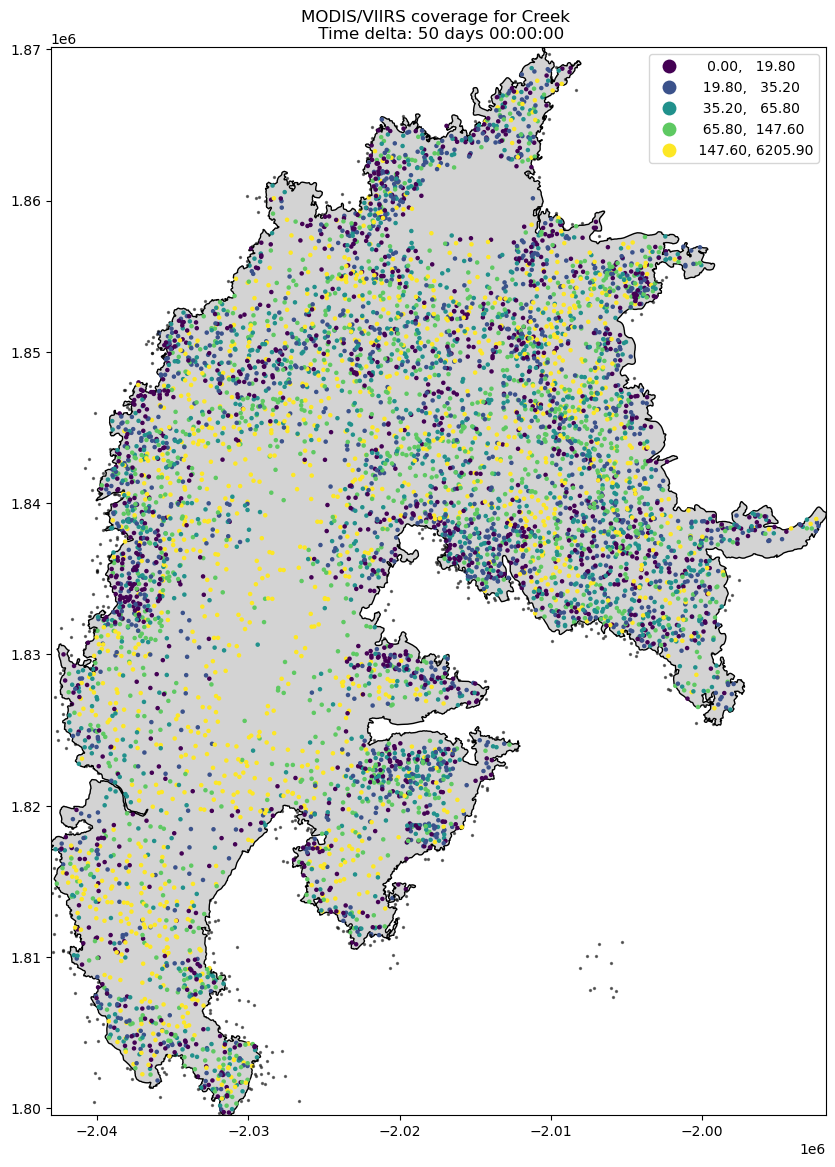

In [85]:
data, fire = plot_points_per_fire(geom_fire=mtbs_per_us,
                     geom_points=all_fire_points_wid,
                     fire_id = 'CA3720111927220200905',
                     variable_to_plot='frp'
                    )

In [77]:
(data
 .filter(['brightness', 'frp', 'fire_id', 'fire_name', 'geometry'])
 .to_file('../data/fire_data_frp_within_fires.shp')
)
(fire
 .filter(['brightness', 'frp', 'fire_id', 'fire_name', 'geometry'])
 .to_file('../data/creek.shp')
)

/Users/topcat/miniconda3/envs/fire/lib/python3.9/site-packages/geopandas/io/file.py:299: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,
/Users/topcat/miniconda3/envs/fire/lib/python3.9/site-packages/geopandas/io/file.py:299: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [86]:
with rasterio.open('../data/test_2_brightness_clip.tif') as src:
    data_bright = src.read(1)
    
with rasterio.open('../data/test_2_clip.tif') as src:
     data_frp = src.read(1)
        
with rasterio.open('/Users/topcat/Downloads/creek_sbs/Creek_SBS_final.tif') as src:
    data = src.read(1)

Text(0.5, 0.69, 'Creek Fire Intensity')

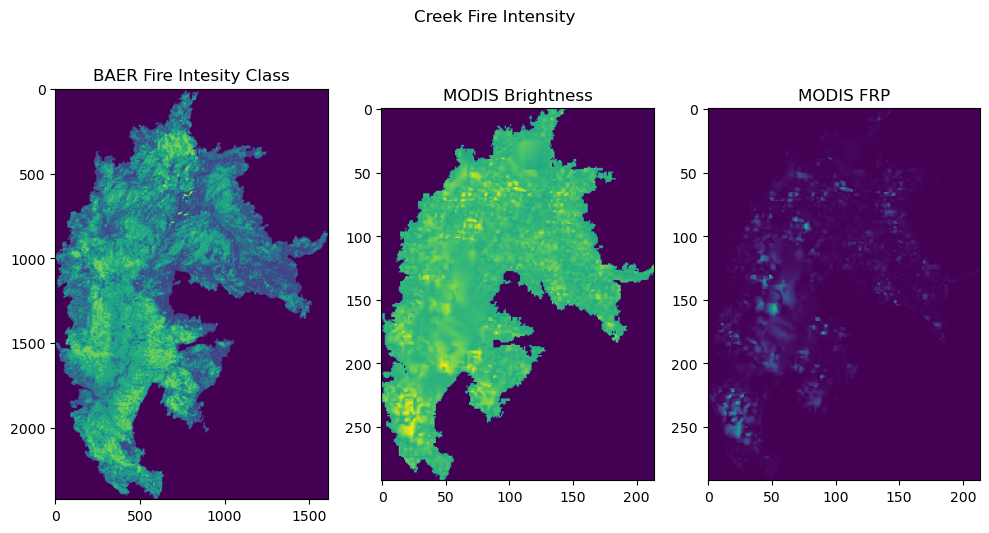

In [113]:
fig, ax = plt.subplots(1, 3, figsize=(10, 15), gridspec_kw={'height_ratios': [1]})
ax[0].imshow(data)
ax[1].imshow(data_bright)
ax[2].imshow(data_frp)

ax[0].set_title('BAER Fire Intesity Class')
ax[1].set_title('MODIS Brightness')
ax[2].set_title('MODIS FRP')
fig.tight_layout()
fig.suptitle('Creek Fire Intensity', y=0.69)

In [116]:
from rasterio.plot import show

{'driver': 'GTiff', 'dtype': 'float64', 'nodata': None, 'width': 1874, 'height': 1768, 'count': 7, 'crs': CRS.from_epsg(4326), 'transform': Affine(0.00026949458523585647, 0.0, 76.83290625074268,
       0.0, -0.00026949458523585647, 28.884699140164333)}


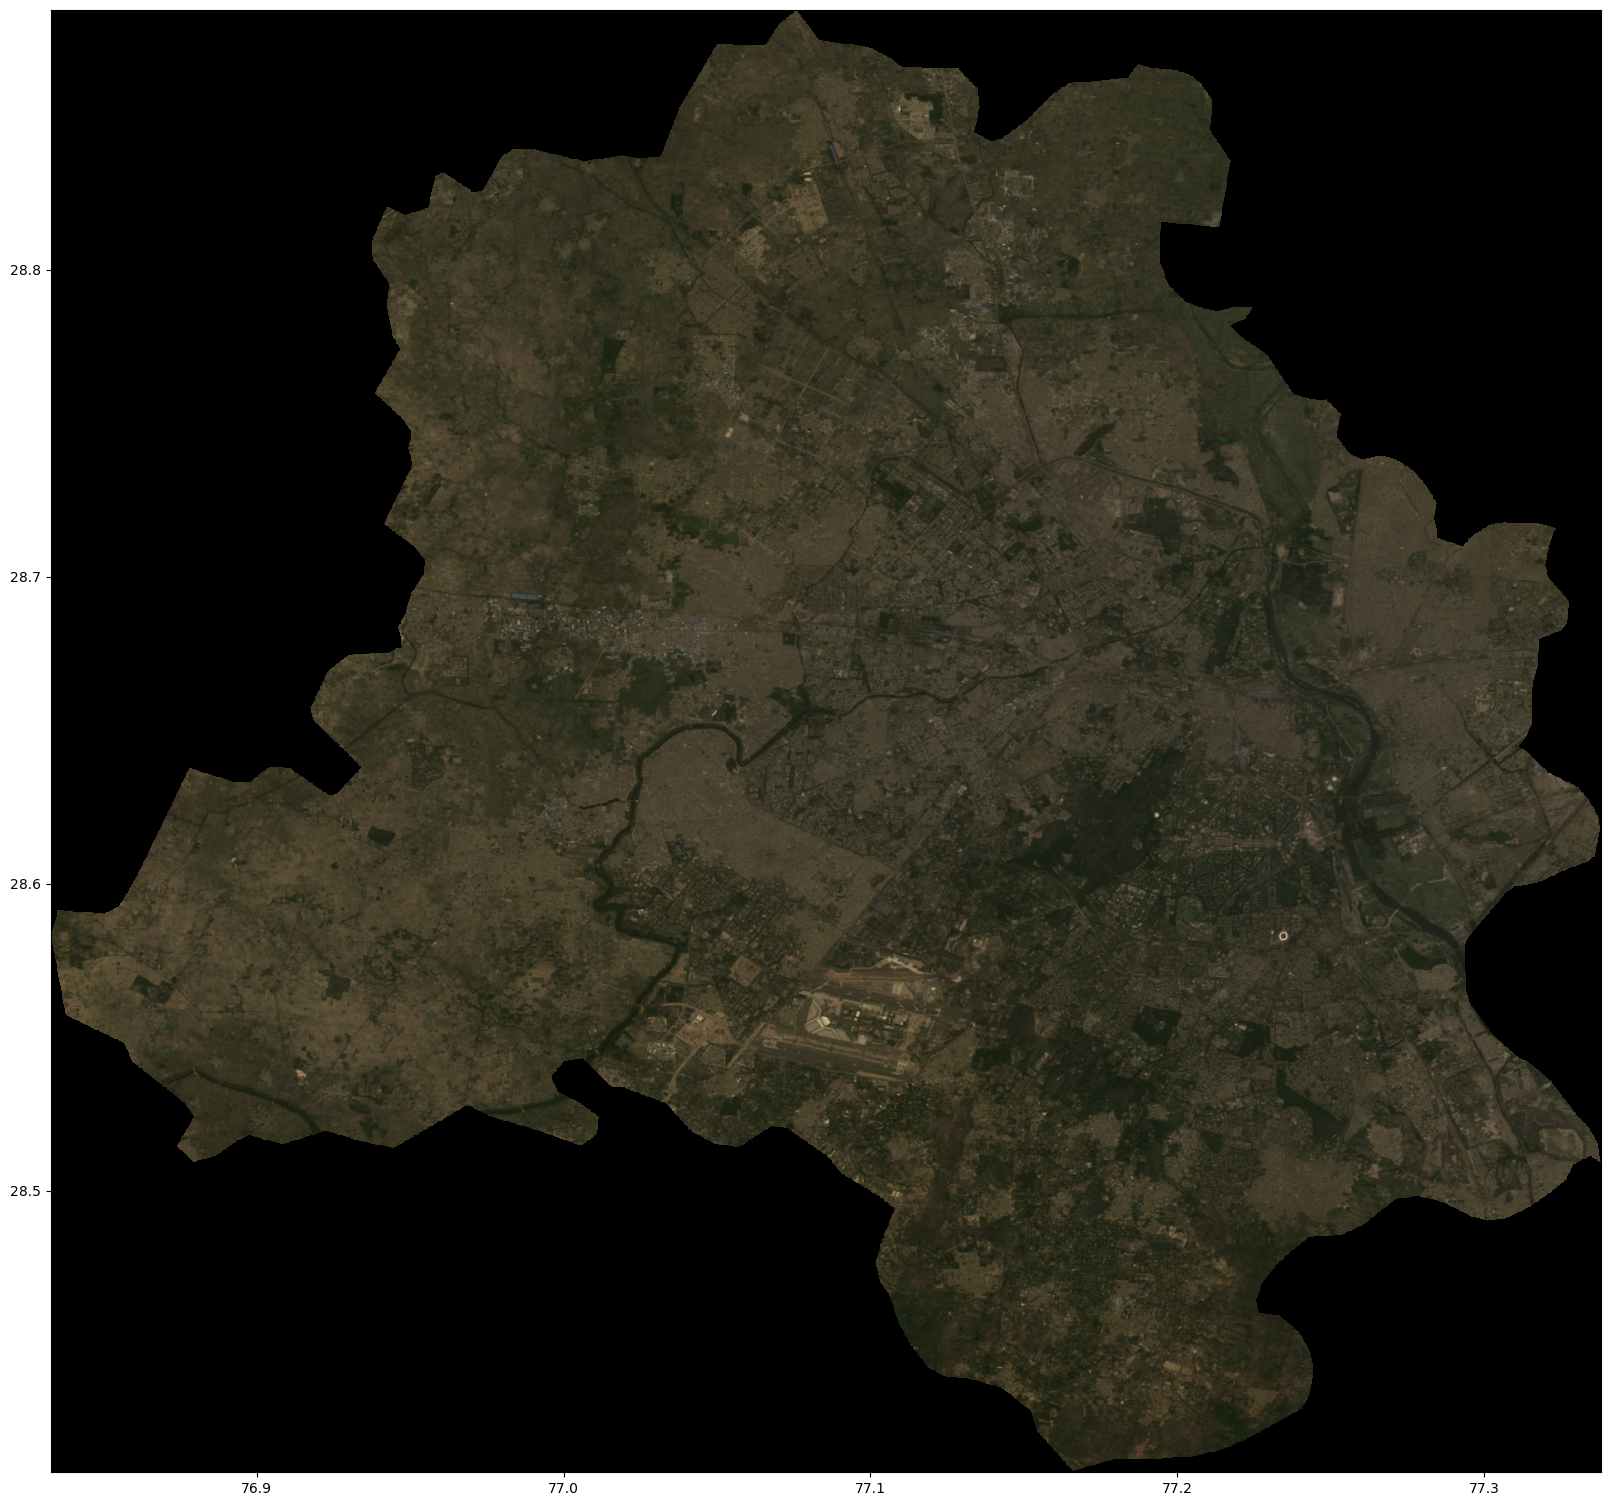

In [135]:
with rasterio.open('/Users/topcat/projects/cs330_project/data/delhi_aoi_30m_2021.tif') as src:
    data = src.read((3, 4, 5))
    print(src.meta)
    fig, ax = plt.subplots(figsize=(20, 20))
    show(data/0.5, transform=src.transform, ax=ax)

In [129]:
data.shape

(3, 1768, 1874)

### GDAL commands

In [ ]:
gdal_grid -a average \
-zfield "brightness" -a linear\
-of GTiff -clipsrc creek.shp \
-ot Float64 fire_data_frp_within_fires.shp test_2_brightness.GTiff

In [ ]:
 gdalwarp -cutline creek.shp test_2.GTiff test_2_clip.tif